# Proyecto Final – Ciencia de Datos con Python
## Predicción del precio por metro cuadrado (m²) de vivienda en arriendo/venta

**Autor:** Liana gamarra  |  **Fuente de datos:** Fincaraíz Colombia (fincaraiz.com.co), arriendo de apartamentos en Medellín – web scraping

**Flujo del proyecto**
1. **Fase I** – Web scraping automatizado con `pandas` + bucles `for`/`while` y URLs dinámicas.
2. **Fase II** – Limpieza: `pd.concat()`, duplicados, NaN, filtros múltiples con `&`/`|`, casteo de tipos.
3. **Fase III** – Análisis exploratorio y visualización.
4. **Fase IV** – Machine Learning: train/test, modelo base (SVR), `GridSearchCV` y validación cruzada (5 folds).

> ⚠️ El portal muestra los anuncios como **tarjetas HTML** (no como `<table>`), así que el HTML se
> descarga con `requests`, se parsea con BeautifulSoup y cada inmueble se convierte en una fila de un DataFrame de pandas.
> Si el sitio cambia su estructura o bloquea las peticiones, ajusta las funciones de la sección 2.

## 0. Librerías

In [ ]:
import re, time, random
from io import StringIO

import numpy as np
import pandas as pd
import requests
from bs4 import BeautifulSoup
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, KFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.svm import SVR
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)
SEMILLA = 42  # reproducibilidad

## 1. Configuración (variables dinámicas)
La URL se construye con **variables dinámicas**: la zona y el número de página cambian en cada iteración del bucle.

In [ ]:
# --- Configuración del scraping -------------------------------------------
BASE_URL    = "https://www.fincaraiz.com.co/arriendo/apartamentos/{zona}"   # {zona} y /pagina{n} son dinámicos
ZONAS       = ["el-poblado/suroriente/medellin",    # regiones/barrios a recorrer (bucle for)
               "laureles/occidente/medellin",
               "belen/suroccidente/medellin",
               "castropol/suroriente/medellin",
               "los-balsos/suroriente/medellin",
               "calasanz/occidente/medellin"]
MAX_PAGINAS = 8                    # tope de páginas por zona (bucle while)
PAUSA_SEG   = (1.5, 3.0)           # pausa aleatoria entre peticiones (respeta al servidor)

HEADERS = {"User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 "
                         "(KHTML, like Gecko) Chrome/124.0 Safari/537.36",
           "Accept-Language": "es-CO,es;q=0.9"}
# --------------------------------------------------------------------------

## 2. Fase I – Web scraping automatizado
- `construir_url` arma la URL con variables dinámicas (zona y número de página).
- `extraer_anuncios` lee las tarjetas de inmuebles y devuelve un DataFrame de pandas.
- Un `for` recorre las zonas y un `while` recorre las páginas hasta que no haya más resultados.

In [ ]:
PATRON_ENLACE = re.compile(r"/(apartamento|apartaestudio|casa|local)-en-arriendo-en-(?:(.+)-)?medellin/(\d+)$")

def construir_url(zona: str, pagina: int) -> str:
    """Construye la URL dinámica. La página 1 no lleva sufijo; las demás usan /paginaN."""
    url = BASE_URL.format(zona=zona)
    return url if pagina == 1 else f"{url}/pagina{pagina}"

def descargar_html(url: str) -> str:
    """Descarga el HTML y lanza excepción si el servidor responde con error (403, 404...)."""
    respuesta = requests.get(url, headers=HEADERS, timeout=25)
    respuesta.raise_for_status()
    return respuesta.text

def extraer_anuncios(html: str) -> pd.DataFrame:
    """Convierte las tarjetas de inmuebles del HTML en un DataFrame (una fila por anuncio)."""
    sopa = BeautifulSoup(html, "html.parser")
    filas = {}                                   # clave = id del anuncio (evita repetidos dentro de la página)
    for enlace in sopa.find_all("a", href=True):
        m = PATRON_ENLACE.search(enlace["href"])
        texto = enlace.get_text(" ", strip=True)
        if not m or "$" not in texto:            # solo la tarjeta con datos (no el enlace del título)
            continue
        tipo, id_anuncio = m.group(1), m.group(3)
        barrio = m.group(2).replace("-", " ") if m.group(2) else "sin barrio"

        precio = re.search(r"\$\s*([\d.]+)", texto)                      # primer precio = canon
        habs   = re.search(r"(\d+)\s*Habs?\.?", texto)
        banos  = re.search(r"(\d+)\s*Ba[ñn]os?", texto)
        area   = re.search(r"([\d.,]+)\s*m²", texto)
        parq   = re.search(r"parqueaderos?\W*(\d+)?\s*(doble|sencillo)?", texto, flags=re.I)

        parqueaderos = None                      # None = el anuncio no lo menciona (se trata como 0 en la limpieza)
        if parq and (parq.group(1) or parq.group(2)):
            tipo_parq = (parq.group(2) or "").lower()
            parqueaderos = 2 if tipo_parq == "doble" else 1 if tipo_parq == "sencillo" else int(parq.group(1))

        filas[id_anuncio] = {
            "id": id_anuncio, "tipo": tipo, "barrio": barrio,
            "precio": precio.group(1) if precio else None,
            "area": area.group(1) if area else None,
            "habitaciones": habs.group(1) if habs else None,
            "banos": banos.group(1) if banos else None,
            "parqueaderos": parqueaderos,
        }
    return pd.DataFrame(filas.values())

In [ ]:
datos_crudos = {}   # diccionario estructurado: clave "zona_pagina" -> DataFrame

for zona in ZONAS:                            # bucle FOR: regiones / barrios
    pagina = 1
    ids_pagina_anterior = set()
    while pagina <= MAX_PAGINAS:              # bucle WHILE: páginas consecutivas
        url = construir_url(zona, pagina)     # URL dinámica
        try:
            tabla = extraer_anuncios(descargar_html(url))
        except Exception as error:
            print(f"[x] {url} -> {error}")
            break
        ids_actuales = set(tabla["id"]) if not tabla.empty else set()
        if tabla.empty or ids_actuales == ids_pagina_anterior:   # sin resultados o página repetida
            print(f"[-] Fin de {zona.split('/')[0]} en la página {pagina}.")
            break

        tabla["zona"] = zona.split("/")[0]    # metadatos para el análisis posterior
        tabla["pagina"] = pagina
        datos_crudos[f"{zona}_{pagina}"] = tabla
        print(f"[+] {zona.split('/')[0]} p.{pagina}: {len(tabla)} anuncios")

        ids_pagina_anterior = ids_actuales
        pagina += 1
        time.sleep(random.uniform(*PAUSA_SEG))

print(f"\nFragmentos descargados: {len(datos_crudos)}")
assert datos_crudos, "No se descargó nada: revisa los mensajes [x] de arriba (URL, bloqueo del sitio o cambios en el HTML)."

[+] el-poblado p.1: 21 anuncios
[+] el-poblado p.2: 21 anuncios
[+] el-poblado p.3: 21 anuncios
[+] el-poblado p.4: 20 anuncios
[+] el-poblado p.5: 21 anuncios
[+] el-poblado p.6: 18 anuncios
[+] el-poblado p.7: 21 anuncios
[+] el-poblado p.8: 20 anuncios
[+] laureles p.1: 20 anuncios
[+] laureles p.2: 21 anuncios
[+] laureles p.3: 20 anuncios
[+] laureles p.4: 21 anuncios
[+] laureles p.5: 21 anuncios
[+] laureles p.6: 21 anuncios
[+] laureles p.7: 20 anuncios
[+] laureles p.8: 21 anuncios
[+] belen p.1: 21 anuncios
[+] belen p.2: 21 anuncios
[+] belen p.3: 21 anuncios
[+] belen p.4: 21 anuncios
[+] belen p.5: 21 anuncios
[+] belen p.6: 21 anuncios
[+] belen p.7: 21 anuncios
[+] belen p.8: 21 anuncios
[+] castropol p.1: 21 anuncios
[+] castropol p.2: 21 anuncios
[+] castropol p.3: 21 anuncios
[+] castropol p.4: 21 anuncios
[+] castropol p.5: 21 anuncios
[+] castropol p.6: 21 anuncios
[+] castropol p.7: 21 anuncios
[+] castropol p.8: 21 anuncios
[+] los-balsos p.1: 21 anuncios
[+] los-

## 3. Fase II – Limpieza y manipulación (Pandas & NumPy)

### 3.1 Concatenación de fragmentos

In [ ]:
df_crudo = pd.concat(datos_crudos.values(), ignore_index=True)
print("Dimensiones crudas:", df_crudo.shape)
df_crudo.head()

Dimensiones crudas: (999, 10)


/tmp/ipykernel_1273/2614870357.py:1: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df_crudo = pd.concat(datos_crudos.values(), ignore_index=True)


,id,tipo,barrio,precio,area,habitaciones,banos,parqueaderos,zona,pagina
0,194551052,apartamento,el poblado,7.000.000,115,3,4,NaN,el-poblado,1
1,194278721,apartamento,el poblado,3.300.000,85,3,3,NaN,el-poblado,1
2,194437640,apartamento,el poblado,5.000.000,64,2,2,NaN,el-poblado,1
3,194559366,apartamento,castropol,6.700.000,130,2,4,1.0,el-poblado,1
4,194469798,apartamento,guayabal,3.700.000,80,3,2,NaN,el-poblado,1


### 3.2 Selección de columnas, duplicados y valores faltantes

In [ ]:
columnas = ["id", "tipo", "barrio", "precio", "area", "habitaciones", "banos", "parqueaderos", "zona"]
df = df_crudo[columnas].copy()

# Duplicados: el mismo inmueble puede aparecer en varias páginas
n_dup = df.duplicated(subset="id").sum()          # mismo anuncio repetido (mismo id) entre páginas/zonas
df = df.drop_duplicates(subset="id").reset_index(drop=True)
print(f"Duplicados eliminados: {n_dup}")

# Diagnóstico de NaN
print("\nNaN por columna (antes):")
print(df.isna().sum())

Duplicados eliminados: 85

NaN por columna (antes):
id                0
tipo              0
barrio            0
precio            0
area              0
habitaciones      0
banos             0
parqueaderos    816
zona              0
dtype: int64


In [ ]:
# Tratamiento justificado de NaN:
# 1) Sin precio o sin área NO se puede calcular el precio por m² (variable objetivo) -> se eliminan.
# 2) Parqueaderos vacío = el inmueble no lo reporta -> se asume 0 (regla de negocio).
# 3) Habitaciones y baños se imputan con la mediana DENTRO del Pipeline de ML (más abajo),
#    para evitar fuga de datos (data leakage) entre train y test.
df = df.dropna(subset=["precio", "area"])
df["parqueaderos"] = df["parqueaderos"].fillna(0)
print("NaN por columna (después):")
print(df.isna().sum())

NaN por columna (después):
id              0
tipo            0
barrio          0
precio          0
area            0
habitaciones    0
banos           0
parqueaderos    0
zona            0
dtype: int64


### 3.3 Conversión explícita de texto a numérico

In [ ]:
def a_numero(serie: pd.Series) -> pd.Series:
    """Convierte textos como '$ 1.250.000', '85 m²' o '3 hab.' a float.
    Elimina todo lo que no sea dígito o coma decimal y castea explícitamente."""
    if pd.api.types.is_numeric_dtype(serie):      # pandas ya la leyó como número (p. ej. 3.0): no tocar
        return serie.astype(float)
    limpio = (serie.astype(str)
                   .str.replace(r"[^\d,]", "", regex=True)   # quita $, m², puntos de miles, letras
                   .str.replace(",", ".", regex=False))        # coma decimal -> punto
    return pd.to_numeric(limpio, errors="coerce")             # lo no convertible queda NaN

def area_a_numero(serie: pd.Series) -> pd.Series:
    """El área puede venir como '108', '121,35' o '1.250' (miles). Se interpreta según el formato."""
    def convertir(x):
        x = str(x).strip()
        if "," in x:
            return pd.to_numeric(x.replace(".", "").replace(",", "."), errors="coerce")
        if re.fullmatch(r"\d{1,3}(\.\d{3})+", x):
            return pd.to_numeric(x.replace(".", ""), errors="coerce")
        return pd.to_numeric(x, errors="coerce")
    return serie.map(convertir)

for col in ["precio", "habitaciones", "banos", "parqueaderos"]:
    df[col] = a_numero(df[col])
df["area"] = area_a_numero(df["area"])

for col in ["zona", "tipo"]:
    df[col] = df[col].astype("category")
df["barrio"] = df["barrio"].astype(str).str.strip().str.title()

# Variable objetivo
df["precio_m2"] = df["precio"] / df["area"]
print(df.dtypes)
df.head()

id                object
tipo            category
barrio            object
precio             int64
area               int64
habitaciones       int64
banos              int64
parqueaderos     float64
zona            category
precio_m2        float64
dtype: object


,id,tipo,barrio,precio,area,habitaciones,banos,parqueaderos,zona,precio_m2
0,194551052,apartamento,El Poblado,7000000,115,3,4,0.0,el-poblado,60869.565217
1,194278721,apartamento,El Poblado,3300000,85,3,3,0.0,el-poblado,38823.529412
2,194437640,apartamento,El Poblado,5000000,64,2,2,0.0,el-poblado,78125.000000
3,194559366,apartamento,Castropol,6700000,130,2,4,1.0,el-poblado,51538.461538
4,194469798,apartamento,Guayabal,3700000,80,3,2,0.0,el-poblado,46250.000000


### 3.4 Filtrado avanzado con condiciones múltiples anidadas

In [ ]:
# Reglas de calidad. Cada condición va entre paréntesis para que Python evalúe bien & y |.
n_antes = len(df)

cond_tipo            = (df["tipo"] == "apartamento") | (df["tipo"] == "apartaestudio")   # excluye casas y locales
cond_valores_validos = (df["precio"] > 0) & (df["area"] > 0) & df["precio_m2"].notna()
cond_area_realista   = (df["area"] >= 15) & (df["area"] <= 500)
cond_habitaciones    = (df["habitaciones"].isna()) | ((df["habitaciones"] >= 0) & (df["habitaciones"] <= 10))
cond_banos           = (df["banos"].isna()) | ((df["banos"] >= 1) & (df["banos"] <= 8))
cond_precio_m2       = (df["precio_m2"] > 0) & (df["precio_m2"] < df["precio_m2"].quantile(0.99))  # recorta extremos

df = df[cond_tipo & cond_valores_validos & cond_area_realista & cond_habitaciones & cond_banos & cond_precio_m2].reset_index(drop=True)
print(f"Filas antes: {n_antes} | después: {len(df)} | eliminadas: {n_antes - len(df)}")

Filas antes: 914 | después: 900 | eliminadas: 14


## 4. Fase III – Análisis exploratorio y visualización
Se observan distribuciones, relaciones con la variable objetivo (`precio_m2`) y correlaciones.

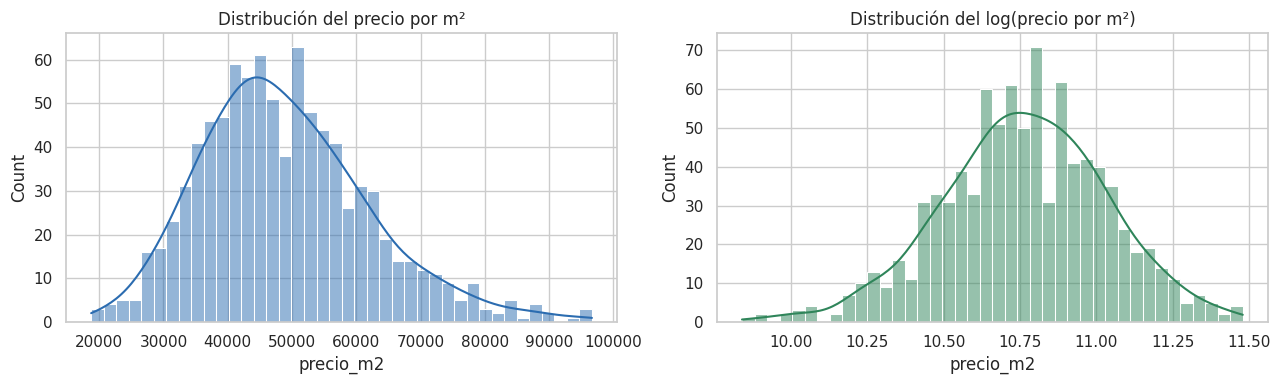

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df["precio_m2"], bins=40, kde=True, ax=axes[0], color="#2b6cb0")
axes[0].set_title("Distribución del precio por m²")
sns.histplot(np.log1p(df["precio_m2"]), bins=40, kde=True, ax=axes[1], color="#2f855a")
axes[1].set_title("Distribución del log(precio por m²)")
plt.tight_layout(); plt.show()

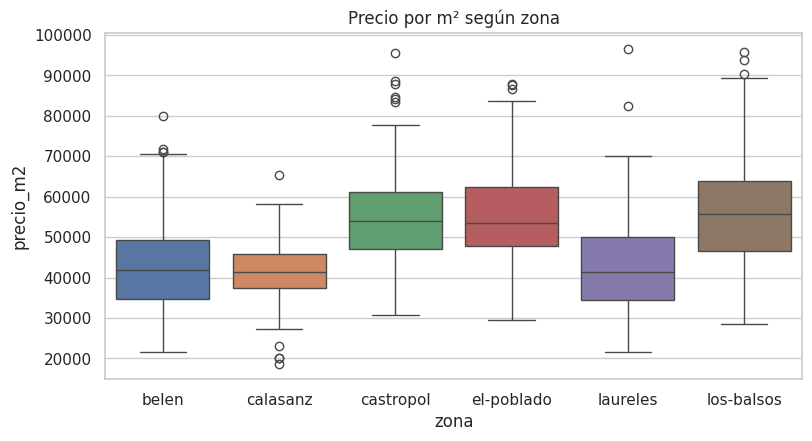

In [ ]:
plt.figure(figsize=(9, 4.5))
sns.boxplot(data=df, x="zona", y="precio_m2", hue="zona", legend=False)
plt.title("Precio por m² según zona"); plt.show()

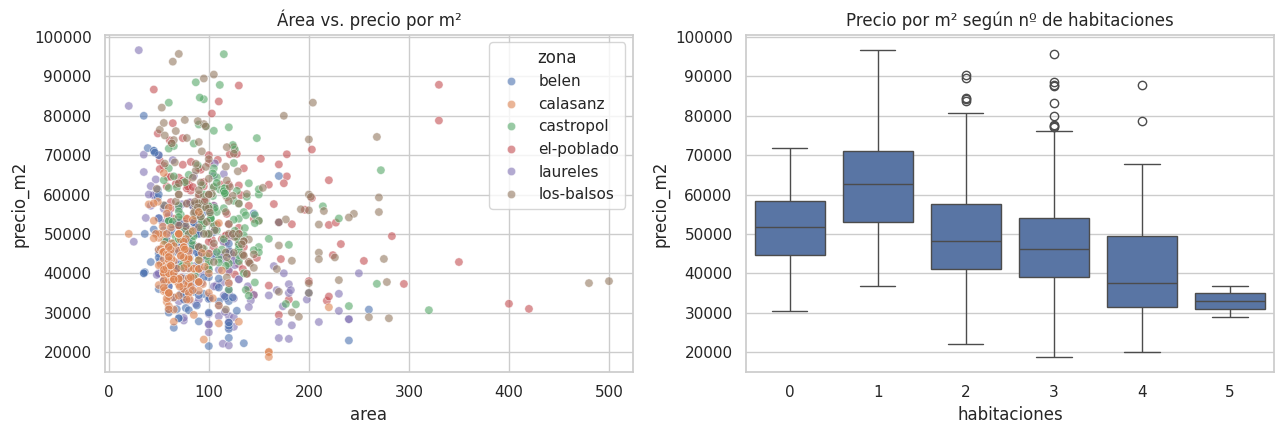

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.scatterplot(data=df, x="area", y="precio_m2", hue="zona", alpha=0.6, ax=axes[0])
axes[0].set_title("Área vs. precio por m²")
sns.boxplot(data=df, x="habitaciones", y="precio_m2", ax=axes[1])
axes[1].set_title("Precio por m² según nº de habitaciones")
plt.tight_layout(); plt.show()

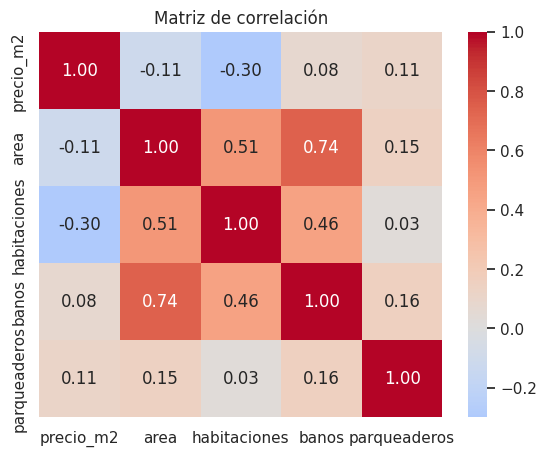

In [ ]:
plt.figure(figsize=(6.5, 5))
sns.heatmap(df[["precio_m2", "area", "habitaciones", "banos", "parqueaderos"]].corr(),
            annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Matriz de correlación"); plt.show()

**Interpretación del análisis exploratorio**

- **Distribución del precio por m²:** se concentra entre unos 35 000 y 55 000 COP/m², con el pico cerca de 45 000 a 50 000 y una cola hacia la derecha que llega hasta unos 95 000. Al aplicar logaritmo la distribución se vuelve mucho más simétrica, por eso en el modelo se transforma la variable objetivo con log.

- **Precio por zona:** Los Balsos es la zona con mayor precio por m² (mediana de
55 814 COP/m²) y Laureles la más económica (mediana de 41 333 COP/m²). Las zonas se separan en dos grupos: Los Balsos, Castropol y El Poblado, con medianas de 53 000 a 56 000 COP/m², y Belén, Calasanz y Laureles, con medianas cercanas a 41 000 a 42 000 COP/m². Dentro de cada grupo las diferencias son pequeñas.
**Área vs. precio por m²:** la relación es débil y ligeramente negativa (correlación de −0.11). Los apartamentos más grandes no son más caros por m²; la mayoría de los inmuebles está entre 40 y 150 m².
- **Habitaciones:** la relación es negativa (−0.30). Los apartamentos de 1 habitación tienen el precio por m² más alto y este baja al aumentar el número de habitaciones. Los de 5 habitaciones son pocos, así que esa caja es poco confiable.
- **Baños y parqueaderos:** casi no se relacionan con el precio por m² (0.08 y 0.11), por lo que aportan poco por sí solos.
- **Relación entre predictores:** el área y los baños están muy correlacionados (0.74), y el área con las habitaciones también (0.51), lo que indica cierta redundancia entre variables.
- **Implicación para el modelo:** el precio por m² depende más de la zona y del tipo de inmueble que del área total, por eso ambas se incluyen como variables categóricas.

## 5. Fase IV – Machine Learning (regresión)

### 5.1 División train / test

In [ ]:
VARIABLES_NUM = ["area", "habitaciones", "banos", "parqueaderos"]
VARIABLES_CAT = ["zona", "tipo"]      # puedes añadir "barrio" si quieres más detalle
OBJETIVO      = "precio_m2"

X = df[VARIABLES_NUM + VARIABLES_CAT]
y = df[OBJETIVO]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEMILLA)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (720, 6) | Test: (180, 6)


In [19]:
df.groupby("zona", observed=True)["precio_m2"].median().sort_values(ascending=False).round(0)

,precio_m2
zona,
los-balsos,55814.0
castropol,53922.0
el-poblado,53417.0
belen,41801.0
calasanz,41379.0
laureles,41333.0


### 5.2 Pipeline + modelo base (SVR)
Todo el preprocesamiento (imputación, escalado, one-hot) vive **dentro del Pipeline**, por lo que en cada fold de la
validación cruzada se ajusta solo con datos de entrenamiento (sin fuga de datos). El objetivo se modela en escala log.

In [ ]:
preprocesador = ColumnTransformer([
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median")),
                      ("scaler", StandardScaler())]), VARIABLES_NUM),
    ("cat", OneHotEncoder(handle_unknown="ignore"), VARIABLES_CAT),
])

modelo_base = TransformedTargetRegressor(
    regressor=Pipeline([("prep", preprocesador), ("svr", SVR())]),   # SVR con parámetros por defecto
    func=np.log1p, inverse_func=np.expm1,
)

cv = KFold(n_splits=5, shuffle=True, random_state=SEMILLA)   # validación cruzada de 5 folds

scores_base = cross_val_score(modelo_base, X_train, y_train, cv=cv, scoring="r2")
score_base_cv = scores_base.mean()
print("R² por fold (modelo base):", np.round(scores_base, 3))
print(f"R² CV medio (ANTES de optimizar): {score_base_cv:.4f} ± {scores_base.std():.4f}")

R² por fold (modelo base): [0.266 0.437 0.412 0.41  0.281]
R² CV medio (ANTES de optimizar): 0.3611 ± 0.0723


### 5.3 Optimización de hiperparámetros con `GridSearchCV`

In [ ]:
param_grid = {
    "regressor__svr__kernel":  ["rbf", "linear"],
    "regressor__svr__C":       [0.1, 1, 10, 100],
    "regressor__svr__epsilon": [0.01, 0.1, 0.2],
    "regressor__svr__gamma":   ["scale", 0.01, 0.1],
}

busqueda = GridSearchCV(modelo_base, param_grid, cv=cv, scoring="r2", n_jobs=-1, verbose=1)
busqueda.fit(X_train, y_train)

print("Mejores hiperparámetros:", busqueda.best_params_)
print(f"R² CV medio (DESPUÉS de optimizar): {busqueda.best_score_:.4f}")

Fitting 5 folds for each of 72 candidates, totalling 360 fits
Mejores hiperparámetros: {'regressor__svr__C': 1, 'regressor__svr__epsilon': 0.01, 'regressor__svr__gamma': 0.01, 'regressor__svr__kernel': 'rbf'}
R² CV medio (DESPUÉS de optimizar): 0.3838


### 5.4 Comparación antes vs. después y evaluación final en test

In [ ]:
mejor_modelo = busqueda.best_estimator_
modelo_base.fit(X_train, y_train)

def evaluar(modelo, nombre):
    pred = modelo.predict(X_test)
    return {"modelo": nombre,
            "R2": r2_score(y_test, pred),
            "MAE": mean_absolute_error(y_test, pred),
            "RMSE": np.sqrt(mean_squared_error(y_test, pred))}

resultados = pd.DataFrame([evaluar(modelo_base, "SVR base"), evaluar(mejor_modelo, "SVR optimizado (GridSearchCV)")])
resultados["R2 CV (train)"] = [score_base_cv, busqueda.best_score_]
print(f"Mejora del R² en validación cruzada: {busqueda.best_score_ - score_base_cv:+.4f}")
resultados.round(4)

Mejora del R² en validación cruzada: +0.0227


,modelo,R2,MAE,RMSE,R2 CV (train)
0,SVR base,0.3382,8212.9024,10534.5619,0.3611
1,SVR optimizado (GridSearchCV),0.3954,7842.1858,10069.3841,0.3838


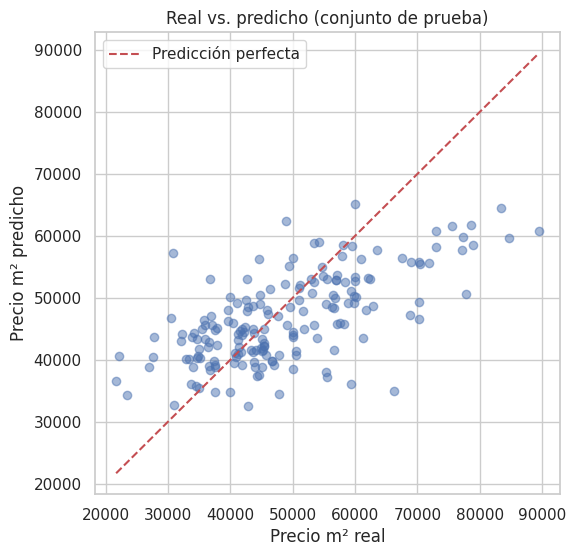

In [ ]:
pred = mejor_modelo.predict(X_test)
plt.figure(figsize=(6, 6))
plt.scatter(y_test, pred, alpha=0.5)
lim = [min(y_test.min(), pred.min()), max(y_test.max(), pred.max())]
plt.plot(lim, lim, "r--", label="Predicción perfecta")
plt.xlabel("Precio m² real"); plt.ylabel("Precio m² predicho")
plt.title("Real vs. predicho (conjunto de prueba)"); plt.legend(); plt.show()

## 6. Conclusiones

**Resultados del modelo.** Se entrenó una regresión SVR para predecir el precio por m² (arriendo mensual, COP/m²) usando 900 anuncios de 6 zonas de Medellín: 720 para entrenamiento y 180 para prueba. El modelo base, con parámetros por defecto, obtuvo un R² medio de 0.361 ± 0.072 en validación cruzada de 5 folds. Tras optimizar con GridSearchCV (72 combinaciones × 5 folds = 360 ajustes), la mejor configuración fue kernel RBF con C = 1, epsilon = 0.01 y gamma = 0.01, y el R² medio subió a 0.384 (+0.023).

| Modelo | R² CV (train) | R² (test) | MAE | RMSE |
|---|---|---|---|---|
| SVR base | 0.361 | 0.338 | 8 213 | 10 535 |
| SVR optimizado (GridSearchCV) | 0.384 | 0.395 | 7 842 | 10 069 |

En el conjunto de prueba el R² pasó de 0.338 a 0.395, y el error medio absoluto bajó de unos 8 200 a unos 7 800 COP/m². La mejora es modesta: en validación cruzada es menor que la variación entre folds (±0.072), por lo que el rendimiento está limitado sobre todo por la información disponible en las variables y no por los hiperparámetros. El modelo explica cerca del 40 % de la variabilidad del precio por m², por lo que sirve como estimación aproximada y no como una valoración precisa. No se observó sobreajuste: los scores de entrenamiento (validación cruzada) y de prueba son parecidos.

**Variables influyentes y limitaciones.** En el análisis exploratorio, el precio por m² se relacionó más con el número de habitaciones (correlación de −0.30: los apartamentos más pequeños son más caros por m²) y con la zona que con el área, los baños o los parqueaderos (correlaciones cercanas a 0.1). Las principales limitaciones son: (1) los datos provienen de un solo portal y de 6 zonas, lo que puede introducir sesgo; (2) los anuncios no incluyen variables clave como estrato, antigüedad o estado del inmueble; (3) hay valores atípicos que se recortaron con filtros de calidad; y (4) la cantidad de parqueaderos se extrajo de la descripción del anuncio y es menos confiable.

**Mejoras posibles.** Incluir más zonas y páginas, agregar variables como estrato, antigüedad o barrio, extender la grilla de hiperparámetros (el mejor gamma quedó en el borde inferior de la grilla) y probar modelos basados en árboles como Random Forest o Gradient Boosting.